# Practice for SQL with Pandas

Import the required libraries and bring in the data.

In [1]:
# Run this code without change

import sqlite3
import pandas as pd
from pandasql import sqldf
from matplotlib import pyplot as plt

conn = sqlite3.Connection('data.sqlite')

1. Read in the products table as a Pandas dataframe.
- Call it `df`
- Look at the first five rows

In [2]:
# Your code here
df = pd.read_sql("""
SELECT * FROM Products
""", conn)
df.head()

,productCode,productName,productLine,productScale,productVendor,productDescription,quantityInStock,buyPrice,MSRP
0,S10_1678,1969 Harley Davidson Ultimate Chopper,Motorcycles,1:10,Min Lin Diecast,"This replica features working kickstand, front...",7933,48.81,95.70
1,S10_1949,1952 Alpine Renault 1300,Classic Cars,1:10,Classic Metal Creations,Turnable front wheels; steering function; deta...,7305,98.58,214.30
2,S10_2016,1996 Moto Guzzi 1100i,Motorcycles,1:10,Highway 66 Mini Classics,"Official Moto Guzzi logos and insignias, saddl...",6625,68.99,118.94
3,S10_4698,2003 Harley-Davidson Eagle Drag Bike,Motorcycles,1:10,Red Start Diecast,"Model features, official Harley Davidson logos...",5582,91.02,193.66
4,S10_4757,1972 Alfa Romeo GTA,Classic Cars,1:10,Motor City Art Classics,Features include: Turnable front wheels; steer...,3252,85.68,136.00


2. Using `read.sql()` from Pandas
- Determine the average MSRP by product line
- Give the average the alias of avgMSRP
- Sort alphabetically A-Z by product line

In [3]:
pd.read_sql("""
SELECT productLine, AVG(MSRP) AS avgMSRP
FROM Products
GROUP BY productline
ORDER BY productLine
""", conn)

,productLine,avgMSRP
0,Classic Cars,118.021053
1,Motorcycles,97.178462
2,Planes,89.515833
3,Ships,86.563333
4,Trains,73.853333
5,Trucks and Buses,103.183636
6,Vintage Cars,87.095833


In [4]:
# Your code here
q = ("""
SELECT productLine, AVG(MSRP) AS avgMSRP
FROM Products
GROUP BY productline
ORDER BY productLine
""")
df_query = pd.read_sql(q, conn)
df_query

,productLine,avgMSRP
0,Classic Cars,118.021053
1,Motorcycles,97.178462
2,Planes,89.515833
3,Ships,86.563333
4,Trains,73.853333
5,Trucks and Buses,103.183636
6,Vintage Cars,87.095833


3. Using matplotlib, create a scatterplot that shows `buyPrice` vs `MSRP`

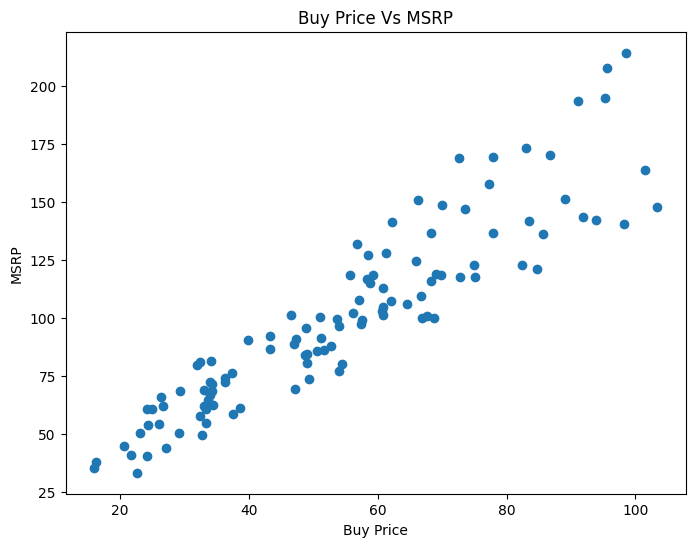

In [5]:
# Your code here
plt.figure(figsize=(8,6))
plt.scatter(df['buyPrice'], df['MSRP'])
plt.xlabel('Buy Price')
plt.ylabel('MSRP')
plt.title('Buy Price Vs MSRP')
plt.show()

4. Use the DataFrame `eval` method in place to find the difference of MSRP and the buy price
- Call this new column `Price_Difference'
- Look at the first five rows
- Give the number of rows

In [6]:
# Your code here
df.eval("Price_Difference = MSRP - buyPrice", inplace=True)
df.head()
len(df)
#rows

110

5. Using matplotlib, create a histogram of `Price_Difference`

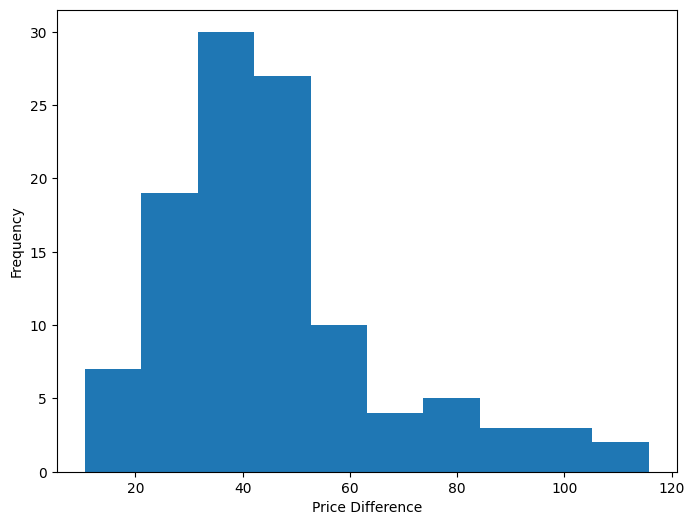

In [7]:
# Your code here
plt.figure(figsize=(8,6))
plt.hist(df['Price_Difference'])
plt.xlabel("Price Difference")
plt.ylabel("Frequency")
plt.show()


6. Using slicing, create a DataFrame that contains 'Price_Difference' that is greater than or equal to $50.
- Call this `df_50'
- Look at the number of rows
  - How does this number compare to the number of rows of `df`?

In [8]:
#Using slicing
df_50 = df[df['Price_Difference'] >= 50]
len(df_50)

32

In [9]:
# Your code here
#using .query()
df_50w = df.query("Price_Difference >= 50")
len(df_50w)

32

In [10]:
len(df) - len(df_50)

78

In [11]:
conn.close()